In [19]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn
from nltk.util import bigrams
from collections import Counter

import experiment
import clslib
import analysis
import smlp

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [21]:
vocab_size = 1000
top_bigrams_num = 10000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

corpus_bigrams = []
for text in train_dataset["sentence"]:
    tokens = bpe_tokenizer.encode(text).tokens
    corpus_bigrams.extend(bigrams(tokens))

top_bigrams = [item for item, _ in Counter(corpus_bigrams).most_common(top_bigrams_num)]
bigram_encoder = clslib.BagOfBigrams(top_bigrams, bpe_tokenizer)

my_classifiers = OrderedDict()

In [22]:
hidden_dim=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['singleMLP_bigram-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/singleMLP_bigram-enc/seed-{seed}"
    my_classifiers['singleMLP_bigram-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bigram_encoder,
            model_option='smlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': hidden_dim, 
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 279.464 seconds
Dataloader done! Time taken: 3.671 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4175 | train acc: 0.8076 | val loss: 0.2735 | val acc: 0.8900
Epoch 02 | train loss: 0.2110 | train acc: 0.9178 | val loss: 0.2428 | val acc: 0.9027
Epoch 03 | train loss: 0.1525 | train acc: 0.9417 | val loss: 0.2451 | val acc: 0.9062
Epoch 04 | train loss: 0.1196 | train acc: 0.9551 | val loss: 0.2556 | val acc: 0.9096
Epoch 05 | train loss: 0.0979 | train acc: 0.9632 | val loss: 0.2642 | val acc: 0.9118
Epoch 06 | train loss: 0.0833 | train acc: 0.9689 | val loss: 0.2850 | val acc: 0.9120
Epoch 07 | train loss: 0.0730 | train acc: 0.9741 | val loss: 0.2920 | val acc: 0.9146
Epoch 08 | train loss: 0.0639 | train acc: 0.9774 | val loss: 0.3177 | val acc: 0.9108
Epoch 09 | train loss: 0.0608 | train acc: 0.9787 | val loss: 0.3181 | val acc: 0.9142
Epoch 10 | train loss: 0.0539 | train acc: 0.9810 | val loss: 0.3371 | val acc: 0.9100
Training done! Time taken: 135.944 seconds
Transforming documents...
Document transformation done! Time taken: 292.720 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4141 | train acc: 0.8108 | val loss: 0.2872 | val acc: 0.8810
Epoch 02 | train loss: 0.2080 | train acc: 0.9192 | val loss: 0.2519 | val acc: 0.8992
Epoch 03 | train loss: 0.1497 | train acc: 0.9426 | val loss: 0.2539 | val acc: 0.9027
Epoch 04 | train loss: 0.1153 | train acc: 0.9570 | val loss: 0.2695 | val acc: 0.9031
Epoch 05 | train loss: 0.0958 | train acc: 0.9653 | val loss: 0.2786 | val acc: 0.9055
Epoch 06 | train loss: 0.0807 | train acc: 0.9714 | val loss: 0.3002 | val acc: 0.9048
Epoch 07 | train loss: 0.0704 | train acc: 0.9743 | val loss: 0.3124 | val acc: 0.9049
Epoch 08 | train loss: 0.0633 | train acc: 0.9773 | val loss: 0.3274 | val acc: 0.9066
Epoch 09 | train loss: 0.0580 | train acc: 0.9793 | val loss: 0.3365 | val acc: 0.9073
Epoch 10 | train loss: 0.0518 | train acc: 0.9814 | val loss: 0.3499 | val acc: 0.9061
Training done! Time taken: 152.852 seconds
Transforming documents...
Document transformation done! Time taken: 295.963 seconds
Dat

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4144 | train acc: 0.8076 | val loss: 0.2942 | val acc: 0.8813
Epoch 02 | train loss: 0.2084 | train acc: 0.9174 | val loss: 0.2650 | val acc: 0.8996
Epoch 03 | train loss: 0.1485 | train acc: 0.9424 | val loss: 0.2701 | val acc: 0.9053
Epoch 04 | train loss: 0.1176 | train acc: 0.9552 | val loss: 0.2827 | val acc: 0.9069
Epoch 05 | train loss: 0.0965 | train acc: 0.9642 | val loss: 0.2966 | val acc: 0.9073
Epoch 06 | train loss: 0.0815 | train acc: 0.9704 | val loss: 0.3109 | val acc: 0.9088
Epoch 07 | train loss: 0.0729 | train acc: 0.9735 | val loss: 0.3320 | val acc: 0.9053
Epoch 08 | train loss: 0.0636 | train acc: 0.9778 | val loss: 0.3461 | val acc: 0.9099
Epoch 09 | train loss: 0.0600 | train acc: 0.9792 | val loss: 0.3589 | val acc: 0.9081
Epoch 10 | train loss: 0.0547 | train acc: 0.9800 | val loss: 0.3731 | val acc: 0.9089
Training done! Time taken: 158.554 seconds
Transforming documents...
Document transformation done! Time taken: 315.339 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4126 | train acc: 0.8093 | val loss: 0.2849 | val acc: 0.8851
Epoch 02 | train loss: 0.2102 | train acc: 0.9171 | val loss: 0.2569 | val acc: 0.9026
Epoch 03 | train loss: 0.1510 | train acc: 0.9423 | val loss: 0.2610 | val acc: 0.9047
Epoch 04 | train loss: 0.1186 | train acc: 0.9558 | val loss: 0.2713 | val acc: 0.9070
Epoch 05 | train loss: 0.0949 | train acc: 0.9652 | val loss: 0.2927 | val acc: 0.9065
Epoch 06 | train loss: 0.0827 | train acc: 0.9705 | val loss: 0.3039 | val acc: 0.9068
Epoch 07 | train loss: 0.0720 | train acc: 0.9744 | val loss: 0.3228 | val acc: 0.9078
Epoch 08 | train loss: 0.0634 | train acc: 0.9772 | val loss: 0.3351 | val acc: 0.9066
Epoch 09 | train loss: 0.0583 | train acc: 0.9789 | val loss: 0.3470 | val acc: 0.9073
Epoch 10 | train loss: 0.0536 | train acc: 0.9805 | val loss: 0.3605 | val acc: 0.9070
Training done! Time taken: 152.239 seconds


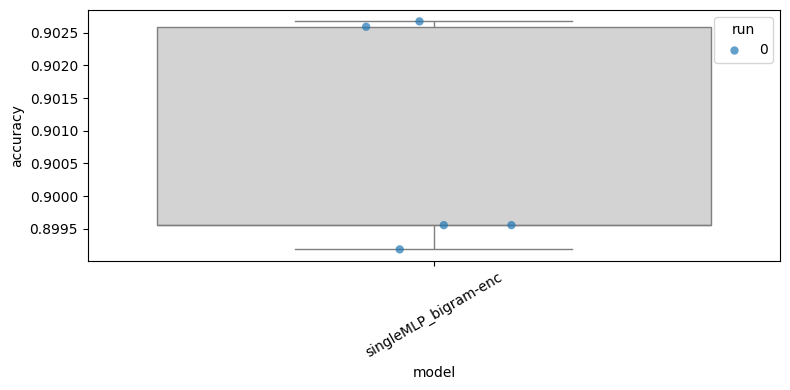

In [23]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [24]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [bigram_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = smlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=smlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/singleMLP_bigram-enc/seed-{seed}/fold-{fold}/model"
        model = smlp.load(model_folder)

        smlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = smlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.6063060481613929, 'accuracy': 0.805045871559633}
              precision    recall  f1-score   support

           0       0.84      0.74      0.79       428
           1       0.78      0.86      0.82       444

    accuracy                           0.81       872
   macro avg       0.81      0.80      0.80       872
weighted avg       0.81      0.81      0.80       872

{'loss': 0.6010786294937134, 'accuracy': 0.7970183486238532}
              precision    recall  f1-score   support

           0       0.83      0.74      0.78       428
           1       0.77      0.85      0.81       444

    accuracy                           0.80       872
   macro avg       0.80      0.80      0.80       872
weighted avg       0.80      0.80      0.80       872

{'loss': 0.604540107447073, 'accuracy': 0.8061926605504587}
              precision    recall  f1-score   support

           0       0.84      0.75      0.79       428
           1       0.78      0.86      0.82       444

 

In [26]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)